In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

In [2]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Notebook_home_250910'

## download the adata object "Xenium_Proseq_pt3_control_neighborhood_261009.h5ad" from the GitHub page"

In [4]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt3_control_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 4315 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans4'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [32]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['Pt3_control_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.519264165154239
Gathering the latent weights


C:\Users\tpeng\anaconda3\envs\scimap\lib\site-packages\scimap\tools\spatial_lda.py:270: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.



In [33]:
adata

AnnData object with n_obs × n_vars = 4315 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

## try 4 clusters ##

In [39]:
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=4, label='spatial_lda_kmeans4')

Kmeans clustering


In [41]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'goldenrod', '1':'olive', '2':'bisque', '3' : 'lightsteelblue'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans4', s =4, alpha = 0.8,  dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt3_control_IC+kera_4clusters_261009.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt3_control_IC+kera_4clusters_261009.png


In [43]:
adata.write_h5ad ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt3_control_neighborhood_261009.h5ad')

In [45]:
adata

AnnData object with n_obs × n_vars = 4315 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans4'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## Generate heatmap ##

In [6]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt3_control_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 4315 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans4'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [7]:
adata.obs.imageid.unique()

['Pt3_control_proseq']
Categories (1, object): ['Pt3_control_proseq']

In [8]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans4"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_29332\2724122214.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans4"].value_counts().unstack()


spatial_lda_kmeans4,0,1,2,3
Cell_label_L3,,,,
Basal keratinocyte,485,886,60,25
CD4 T cell_FOXP3+,3,20,0,44
CD4 T cell_GZMBlow,4,18,0,63
CD8 T cell_GZMBlow,6,23,2,62
DC_LAMP3+,2,3,0,4
Granulosum keratinocyte_KRT2+,1121,53,48,0
Langerhans cell,18,21,4,14
Mac_ISGlow,10,27,1,170
Mast cell,2,6,0,37


In [9]:
frequency_table = (df / df.sum())*100

pd.options.display.float_format = '{:.2f}'.format

In [10]:
# Define your desired custom order
custom_order = ['0', '1', '2','3']
frequency_table = frequency_table[custom_order]

frequency_table.columns = ['N0','N1','N2','N3']
frequency_table.head(n=2)

,N0,N1,N2,N3
Cell_label_L3,,,,
Basal keratinocyte,26.58,52.96,17.54,5.26
CD4 T cell_FOXP3+,0.16,1.20,0.00,9.26


In [11]:
list2 = [
 'Granulosum keratinocyte_KRT2+',
 'Spinosum keratinocyte_KRT2+',
 'Basal keratinocyte',

 'CD8 T cell_GZMBlow','CD4 T cell_GZMBlow','CD4 T cell_FOXP3+','Mac_ISGlow','Langerhans cell','Mast cell','DC_LAMP3+','cDC1','cDC2'
]

# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)

frequency_table.index = [
 'Granu kera_KRT2+',
 'Spino kera_KRT2+',
 'Basal kera',

 'CD8 T_GZMBlow','CD4 T_GZMBlow','CD4 T_FOXP3+','Mac_ISGlow','Langerhans','Mast','DC_LAMP3+','cDC1','cDC2'
]
frequency_table

,N0,N1,N2,N3
Granu kera_KRT2+,61.42,3.17,14.04,0.00
Spino kera_KRT2+,8.88,33.53,64.91,0.21
Basal kera,26.58,52.96,17.54,5.26
CD8 T_GZMBlow,0.33,1.37,0.58,13.05
CD4 T_GZMBlow,0.22,1.08,0.00,13.26
CD4 T_FOXP3+,0.16,1.20,0.00,9.26
Mac_ISGlow,0.55,1.61,0.29,35.79
Langerhans,0.99,1.26,1.17,2.95
Mast,0.11,0.36,0.00,7.79
DC_LAMP3+,0.11,0.18,0.00,0.84


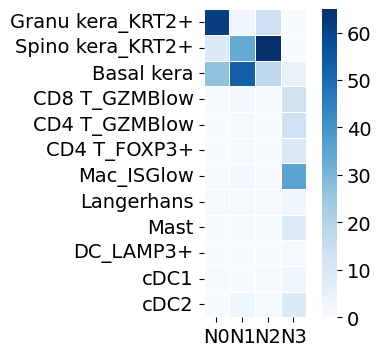

In [12]:
plt.figure(figsize=(4, 4)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()